# Fitting circles to things and like the baseline and all that

In [2]:
from dependencies import *;

# 1) Uncertainty in fitting a circle for different baselines

In [ ]:
def generate_datapoints(n_points, radius, sigma, baseline=0.5, evenly_sampled=True):
    """
    Generate datapoints around a circle with noise
    
    parameters:
        n_points: number of points to generate
        radius: radius of the circle
        sigma: standard deviation, as fraction of the radius
        baseline: how much of the circle we"re sampling, 0.5 means half the circle, 1 means full circle
    
    returns:
        x, y: coordinates of the generated points
    """
    
    # choose the angles at which to sample the points
    if evenly_sampled:
        angles = np.linspace(0, 2*np.pi * baseline, n_points)
    else:
        angles = np.zeros(n_points)
        angles[0] = 0
        angles[-1] = 2*np.pi * baseline
        angles[1:-1] = np.random.uniform(0, 2*np.pi * baseline, n_points - 2)

    # assign the radial extent based on the normal distribution
    radial_distances = np.random.normal(loc=radius, scale=sigma * radius, size=n_points)
    
    # return x, y coordinates of the points
    return radial_distances * np.cos(angles), radial_distances * np.sin(angles) 

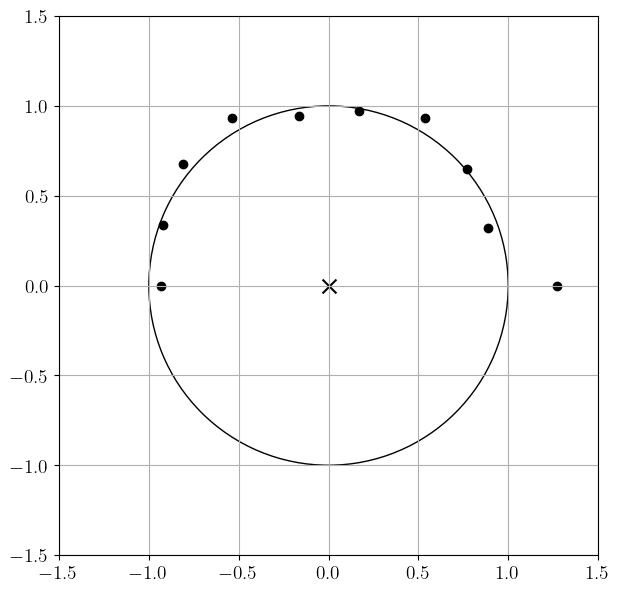

In [74]:
RADIUS = 1
SIGMA = 0.1
BASELINE = 0.5
N_POINTS = 10

fig, ax = plt.subplots(1,1, figsize=(7,7))
ax.grid(visible=True)
ax.set_xlim(RADIUS * -1.5, RADIUS * 1.5)
ax.set_ylim(RADIUS * -1.5, RADIUS * 1.5)
ax.set_aspect("equal")

# Draw the circle for reference
circle = plt.Circle((0, 0), RADIUS, color="black", fill=False)
ax.add_artist(circle)
ax.scatter(0,0, color="black", marker="x", s=100)

# show the datapoints
x, y = generate_datapoints(N_POINTS, RADIUS, SIGMA, BASELINE)
ax.scatter(x, y)

plt.show()

In [75]:
def fit_circle_with_uncertainties(x, y, uncertainties=None):
    """
    Fit a circle to the given x, y points using least squares method,
    taking into account the uncertainties in the measurements,
    and estimating the uncertainties in the fitted parameters.
    
    parameters:
        x: x-coordinates of the points
        y: y-coordinates of the points  
        uncertainties: uncertainties in the measurements (optional)
    returns:
        tuple: (center_x, center_y, radius) of the fitted circle
    """
    # Assemble the A matrix and b vector for least squares fitting
    A = np.c_[x, y, np.ones(x.shape[0])]
    b = x**2 + y**2

    if uncertainties is not None:
        # Weight the data by the inverse of the uncertainties
        W = np.diag(1 / (uncertainties**2))
        A = np.dot(W, A)
        b = np.dot(W, b)

    # Solve the least squares problem
    c, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)

    # Extract the circle parameters
    center_x = c[0] / 2
    center_y = c[1] / 2
    radius = np.sqrt(center_x**2 + center_y**2 + c[2])
    
    # Estimate uncertainties in the fitted parameters
    if uncertainties is not None:
        # Calculate the covariance matrix of the fitted parameters
        cov_matrix = np.linalg.inv(A.T @ A)
        param_uncertainties = np.sqrt(np.diag(cov_matrix))
        center_x_uncertainty = param_uncertainties[0] / 2
        center_y_uncertainty = param_uncertainties[1] / 2
        radius_uncertainty = np.sqrt((center_x * center_x_uncertainty)**2 + (center_y * center_y_uncertainty)**2 + (param_uncertainties[2])**2)
        
        return (center_x, center_y, radius), (center_x_uncertainty, center_y_uncertainty, radius_uncertainty)

    return center_x, center_y, radius

In [87]:
# fit an example
RADIUS = 1
SIGMA = 0.05
BASELINE = 0.5
N_POINTS = 20

x, y = generate_datapoints(N_POINTS, RADIUS, SIGMA, BASELINE, evenly_sampled=False)
res = fit_circle_with_uncertainties(x, y, uncertainties=np.full_like(x, SIGMA * RADIUS))

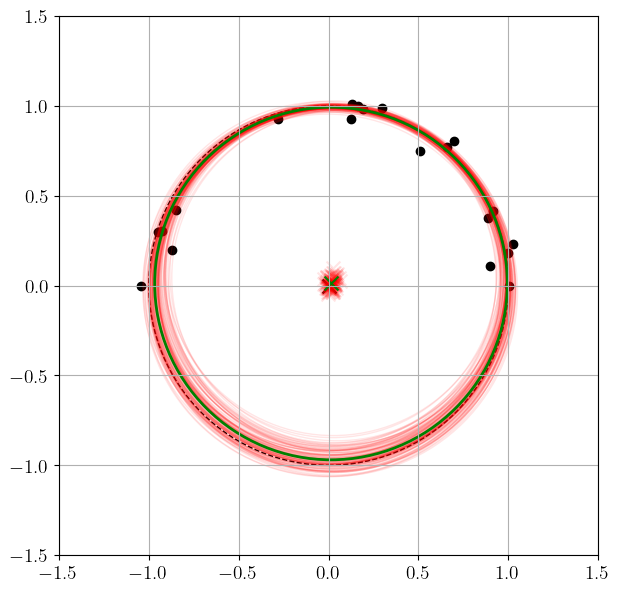

In [88]:
fig, ax = plt.subplots(1,1, figsize=(7,7))
ax.grid(visible=True)
ax.set_xlim(RADIUS * -1.5, RADIUS * 1.5)
ax.set_ylim(RADIUS * -1.5, RADIUS * 1.5)
ax.set_aspect("equal")

# Draw the circle for reference
circle = plt.Circle((0, 0), RADIUS, color="k", ls="--", fill=False)
ax.add_artist(circle)
ax.scatter(0,0, color="k", marker="x", s=100)

# show the datapoints
ax.scatter(x, y)

# bootstrap to show range of fitted circles
n_bootstrap = 100
bootstrap_results = []
for _ in range(n_bootstrap):
    # Resample the data with replacement
    indices = np.random.choice(len(x), len(x), replace=True)
    x_resampled = x[indices]
    y_resampled = y[indices]
    
    # Fit the circle to the resampled data
    res_bootstrap = fit_circle_with_uncertainties(x_resampled, y_resampled, uncertainties=np.full_like(x_resampled, SIGMA * RADIUS))
    bootstrap_results.append(res_bootstrap)
bootstrap_results = np.array(bootstrap_results)

# Plot the bootstrap fitted circles
for res_bootstrap in bootstrap_results:
    fitted_circle_bootstrap = plt.Circle((res_bootstrap[0][0], res_bootstrap[0][1]), res_bootstrap[0][2], color="r", alpha=0.1, fill=False)
    ax.add_artist(fitted_circle_bootstrap)
    ax.scatter(res_bootstrap[0][0], res_bootstrap[0][1], color="r", marker="x", alpha=0.1, s=100)

# show the fitted circle
fitted_circle = plt.Circle((res[0][0], res[0][1]), res[0][2], color="g", fill=False, lw=2)
ax.add_artist(fitted_circle)
ax.scatter(res[0][0], res[0][1], color="g", marker="x", s=100)

plt.show()

In [109]:
RADIUS = 1
SIGMA = 0.03
N_POINTS = 20
TIMES_SAMPLED = 50
N_BASELINES = 100

baselines = np.linspace(0.1, 1.0, N_BASELINES)
results = []
for baseline in tqdm(baselines):
    temp_results = []
    for _ in range(TIMES_SAMPLED):
        x, y = generate_datapoints(N_POINTS, RADIUS, SIGMA, baseline, evenly_sampled=True)
        res = fit_circle_with_uncertainties(x, y, uncertainties=np.full_like(x, SIGMA * RADIUS))
        temp_results.append(res)
    temp_results = np.array(temp_results)
    results.append(np.mean(temp_results, axis=0))
results = np.array(results)

  0%|          | 0/100 [00:00<?, ?it/s]

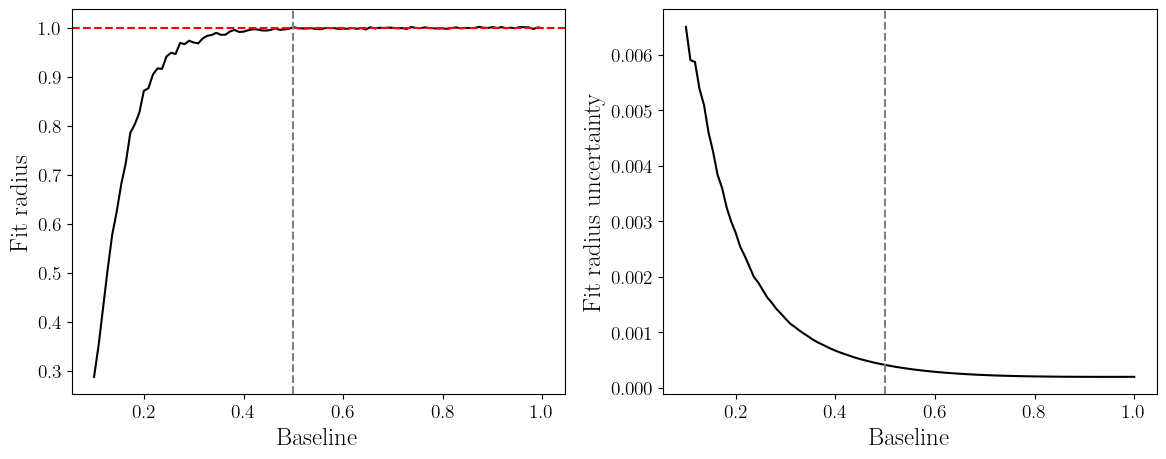

In [110]:
fig, axs = plt.subplots(1,2, figsize=(14,5))

ax = axs[0]
ax.plot(baselines, [r[0][2] for r in results])
ax.axhline(y=RADIUS, color="r", linestyle="--")
ax.set_xlabel("Baseline")
ax.set_ylabel("Fit radius")
ax.axvline(x=0.5, c="grey", ls="--")

ax = axs[1]
ax.plot(baselines, [r[1][2] for r in results])
ax.set_xlabel("Baseline")
ax.set_ylabel("Fit radius uncertainty")
ax.axvline(x=0.5, c="grey", ls="--")

plt.show()

# 2) Simple ellipse

In [132]:
def generate_ellipse_datapoints(n_points, a, e, sigma, w=0, t_p=0, baseline=0.5, evenly_sampled=True):
    """
    Generate datapoints around an ellipse centred at one of the foci, with noise
    
    parameters:
        n_points: number of points to generate
        a: semi-major axis of the ellipse
        e: eccentricity of the ellipse
        w: argument of periapsis (orientation of the ellipse), in radians
        t_p: time of periapsis passage, in radians (will just shift the angle)
        sigma: standard deviation, as fraction of the radius
        baseline: how much of the circle we"re sampling, 0.5 means half the circle, 1 means full circle
    
    returns:
        x, y: coordinates of the generated points
    """
    
    # choose the angles at which to sample the points
    if evenly_sampled:
        angles = np.linspace(0, 2*np.pi * baseline, n_points)
    else:
        angles = np.zeros(n_points)
        angles[0] = 0
        angles[-1] = 2*np.pi * baseline
        angles[1:-1] = np.random.uniform(0, 2*np.pi * baseline, n_points - 2)
    
    angles += t_p  # shift angles by time of periapsis passage

    # assign the radial extent based on the normal distribution
    radius = a * (1 - e**2) / (1 + e * np.cos(angles))  # radial distance for an ellipse
    # the uncertainty will be a fraction of the semi-major axis
    radial_distances = np.random.normal(loc=radius, scale=sigma*a, size=n_points)
    
    # return x, y coordinates of the points
    return radial_distances * np.cos(angles + w), radial_distances * np.sin(angles + w) 

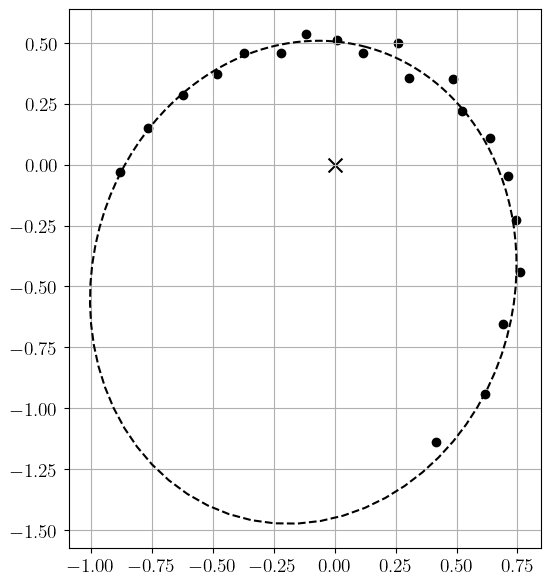

In [141]:
SEMI_MAJOR_AXIS = 1
ECCENTRICITY = 0.5
SIGMA = 0.03
ARGUMENT_OF_PERIAPSIS = np.deg2rad(75)
TIME_OF_PERIAPSIS = np.deg2rad(215)
BASELINE = 0.7
N_POINTS = 20

fig, ax = plt.subplots(1,1, figsize=(7,7))
ax.grid(visible=True)
ax.set_aspect("equal")

# Draw the ellipse for reference
angles = np.linspace(0, 2*np.pi, 100)
ellipse_x = SEMI_MAJOR_AXIS * (1 - ECCENTRICITY**2) / (1 + ECCENTRICITY * np.cos(angles)) * np.cos(angles + ARGUMENT_OF_PERIAPSIS)
ellipse_y = SEMI_MAJOR_AXIS * (1 - ECCENTRICITY**2) / (1 + ECCENTRICITY * np.cos(angles)) *np.sin(angles + ARGUMENT_OF_PERIAPSIS)
ax.plot(ellipse_x, ellipse_y, color="black", ls="--")
ax.scatter(0,0, color="black", marker="x", s=100)

# show the datapoints
x, y = generate_ellipse_datapoints(N_POINTS, SEMI_MAJOR_AXIS, ECCENTRICITY, SIGMA, 
                                   w=ARGUMENT_OF_PERIAPSIS, t_p=TIME_OF_PERIAPSIS, baseline=BASELINE)
ax.scatter(x, y)

plt.show()

In [149]:
def fit_ellipse_with_uncertainties(x, y, uncertainties=None):
    """
    Fit an ellipse to the given x, y points using least squares method,
    taking into account the uncertainties in the measurements,
    and estimating the uncertainties in the fitted parameters.
    
    parameters:
        x: x-coordinates of the points
        y: y-coordinates of the points  
        uncertainties: uncertainties in the measurements (optional)
    returns:
        tuple: (center_x, center_y, semi_major_axis, eccentricity, argument_of_periapsis) of the fitted ellipse
    """
    
    # Assemble the A matrix and b vector for least squares fitting
    A = np.c_[x**2, x*y, y**2, x, y, np.ones(x.shape[0])]
    b = np.ones(x.shape[0])
    
    # If uncertainties are provided, weight the data by the inverse of the uncertainties
    if uncertainties is not None:
        W = np.diag(1 / (uncertainties**2))
        A = np.dot(W, A)
        b = np.dot(W, b)
        
    # Solve the least squares problem
    c, residuals, rank, s = np.linalg.lstsq(A, b, rcond=None)
    
    # Extract the ellipse parameters
    a = c[0]
    b = c[1]
    c = c[2]
    
    # Calculate the center of the ellipse
    center_x = (b*c - 2*a*c) / (4*a*c - b**2)
    center_y = (b*a - 2*c*a) / (4*a*c - b**2)
    
    # Calculate the semi-major axis and eccentricity
    semi_major_axis = np.sqrt(1 / (a + c - np.sqrt((a - c)**2 + b**2)))
    semi_minor_axis = np.sqrt(1 / (a + c + np.sqrt((a - c)**2 + b**2)))
    eccentricity = np.sqrt(1 - (semi_minor_axis**2 / semi_major_axis**2))
    
    # Calculate the argument of periapsis
    argument_of_periapsis = 0.5 * np.arctan2(b, a - c)
    
    # Estimate uncertainties in the fitted parameters
    if uncertainties is not None:
        # Calculate the covariance matrix of the fitted parameters
        cov_matrix = np.linalg.inv(A.T @ A)
        param_uncertainties = np.sqrt(np.diag(cov_matrix))
        
        center_x_uncertainty = param_uncertainties[3]
        center_y_uncertainty = param_uncertainties[4]
        semi_minor_axis_uncertainty = param_uncertainties[5]
        semi_major_axis_uncertainty = param_uncertainties[0]
        eccentricity_uncertainty = param_uncertainties[1]
        argument_of_periapsis_uncertainty = param_uncertainties[2]
        
        return (center_x, center_y, semi_major_axis, eccentricity, argument_of_periapsis), (center_x_uncertainty, center_y_uncertainty, semi_major_axis_uncertainty, eccentricity_uncertainty, argument_of_periapsis_uncertainty)
    

In [160]:
# fit an example
SEMI_MAJOR_AXIS = 1
ECCENTRICITY = 0.5
SIGMA = 0.03
ARGUMENT_OF_PERIAPSIS = np.deg2rad(75)
TIME_OF_PERIAPSIS = np.deg2rad(215)
BASELINE = 0.5
N_POINTS = 20

x, y = generate_ellipse_datapoints(N_POINTS, SEMI_MAJOR_AXIS, ECCENTRICITY, SIGMA, 
                                   w=ARGUMENT_OF_PERIAPSIS, t_p=TIME_OF_PERIAPSIS, baseline=BASELINE)
res = fit_ellipse_with_uncertainties(x, y, uncertainties=np.full_like(x, SIGMA * RADIUS))

In [161]:
res

((-0.4765672594169497,
  -0.08783372158534077,
  26276936.569286015,
  0.894775739297387,
  0.32858497654072955),
 (0.003723381544046478,
  0.003402950604383098,
  0.00793270035963423,
  0.004038127199737328,
  0.0036994051536455856))

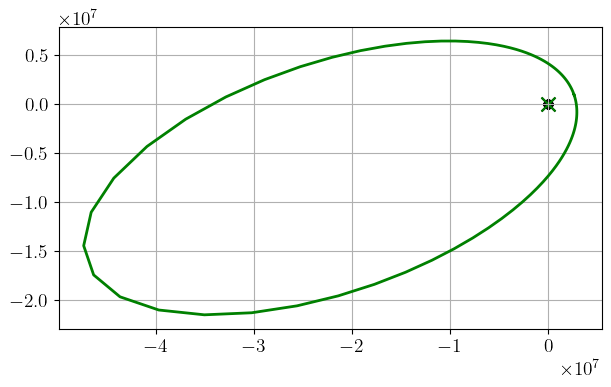

In [162]:
fig, ax = plt.subplots(1,1, figsize=(7,7))
ax.grid(visible=True)
ax.set_aspect("equal")
# Draw the ellipse for reference
angles = np.linspace(0, 2*np.pi, 100)
ellipse_x = SEMI_MAJOR_AXIS * (1 - ECCENTRICITY**2) / (1 + ECCENTRICITY * np.cos(angles)) * np.cos(angles + ARGUMENT_OF_PERIAPSIS)
ellipse_y = SEMI_MAJOR_AXIS * (1 - ECCENTRICITY**2) / (1 + ECCENTRICITY * np.cos(angles)) *np.sin(angles + ARGUMENT_OF_PERIAPSIS)
ax.plot(ellipse_x, ellipse_y, color="black", ls="--")
ax.scatter(0,0, color="black", marker="x", s=100)

# show the datapoints
ax.scatter(x, y)

# show the fitted ellipse
fitted_ellipse_x = res[0][2] * (1 - res[0][3]**2) / (1 + res[0][3] * np.cos(angles)) * np.cos(angles + res[0][4]) + res[0][0]
fitted_ellipse_y = res[0][2] * (1 - res[0][3]**2) / (1 + res[0][3] * np.cos(angles)) * np.sin(angles + res[0][4]) + res[0][1]
ax.plot(fitted_ellipse_x, fitted_ellipse_y, color="g", lw=2)
ax.scatter(res[0][0], res[0][1], color="g", marker="x", s=100)

plt.show()